In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from sklearn.model_selection import train_test_split
import torch
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torch.nn.functional as F
import pandas as pd
from scipy.spatial.distance import euclidean
import numpy as np
import time
import matplotlib.pyplot as plt
from torch.nn import Module
from sklearn.metrics import r2_score

In [3]:
class GRU_Model(nn.Module):
    def __init__(self, time_lag=72, pred_horizon=4, num_stations=9, num_layers = 2):
        super(GRU_Model, self).__init__()

        self.pred_horizon = pred_horizon
        self.num_stations = num_stations

        # 3D Convolution Layer
        # cnn_out_channels = 64
        # self.conv3d = nn.Conv3d(in_channels=1, out_channels=cnn_out_channels, kernel_size=(1, number_of_similars, 1))
        self.activation = nn.SELU()

        # GRU Layer
        hidden_size=64 * num_stations * pred_horizon
        self.gru = nn.GRU(input_size=num_stations, hidden_size=hidden_size, num_layers=num_layers, batch_first=True, dropout=0.02)

        # Fully connected layer for main model output
        fc_main_output_size = 250
        self.fc_main = nn.Linear(hidden_size, fc_main_output_size)

        # Fully connected layer for auxiliary input (72, 3) -> flattened and mapped to 100 neurons
        aux_data_len=3
        fc_aux_output_size=100
        self.fc_aux = nn.Linear(time_lag * aux_data_len, fc_aux_output_size)

        # Fully connected layer after concatenating the main and aux inputs
        fc_concat1_output_size = 100
        self.fc_concat1 = nn.Linear(fc_main_output_size+fc_aux_output_size, fc_concat1_output_size)
        self.fc_concat2 = nn.Linear(fc_concat1_output_size, num_stations * pred_horizon)


    def forward(self, x, aux_input):
        x = x.unsqueeze(1)  # Shape: (batch_size, 1, 9, 4, 12)
        # x = self.conv3d(x)  # Shape: (batch_size, 64, 9, 1, 12)
        # x = self.activation(x)
        # input shape: batch_size, 1, 9, 1, pred_horizon
        x = x.permute(0, 4, 1, 2, 3).contiguous()  # Shape: (batch_size, pred_horizon, 1, 9, 1)
        x = x.view(x.size(0), x.size(1), -1)  # Shape: (batch_size, pred_horizon, 9)
        x, _ = self.gru(x)  # Shape: (batch_size, time_lag, hidden_size)
        x = x[:, -1, :]  # Take the last time step's output -> Shape: (batch_size, hidden_size)
        x = self.fc_main(x)  # Shape: (batch_size, 250)

        # Auxiliary input processing (flatten first)
        aux_input = aux_input.view(aux_input.size(0), -1)  # Flatten (batch_size, 72 * 3)
        aux_out = self.fc_aux(aux_input)  # Shape: (batch_size, 100)
        aux_out = self.activation(aux_out)

        # Concatenate the main model output and auxiliary input
        combined = torch.cat((x, aux_out), dim=1)  # Shape: (batch_size, 250 + 100)

        # Final fully connected layer to get output (batch_size, 9 * 5)
        output = self.fc_concat1(combined)  # Shape: (batch_size, 9 * 5)
        output = self.activation(output)
        output = self.fc_concat2(output)
        output = output.view(output.size(0), self.num_stations, self.pred_horizon)  # Reshape to (batch_size, 9, 5)

        return output

    def train_model_early_stop(self, num_epochs, train_loader, valid_loader, batch_size, optimizer, criterion, device, patience=3):
        last_valid_loss = float('inf')
        epochs_no_improve = 0
        early_stop = False

        train_loss_history = []
        val_loss_history = []
        start_time = time.time()
        trained_epochs = 0

        for epoch in range(num_epochs):
            if early_stop:
                break
            trained_epochs += 1
            train_epoch_iterator = tqdm(train_loader, desc="Training")
            epoch_loss = self.train_epoch(train_epoch_iterator, optimizer, criterion, device)
            val_loss = self.get_eval_factors(valid_loader, batch_size, criterion, device)
            r2_scores = self.calculate_r2_score(valid_loader)

            train_loss_history += [epoch_loss]
            val_loss_history += [val_loss]
            print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}, R2_Score: {sum(r2_scores)/len(r2_scores):.4f}')

        # Early stopping
            if val_loss < last_valid_loss:
                last_valid_loss = val_loss
                epochs_no_improve = 0
                best_model_wts = self.state_dict()
            else:
                epochs_no_improve += 1

            if epochs_no_improve >= patience:
                print(f'Early stopping triggered after {epoch+1} epochs')
                early_stop = True

        end_time = time.time()
        training_time = end_time - start_time
        print(f'Total Training Time: {training_time:.2f} seconds')

        if early_stop:
            self.load_state_dict(best_model_wts)

        return (train_loss_history, val_loss_history, trained_epochs)

    def train_epoch(self, train_loader, optimizer, criterion, device):
        self.train()
        running_loss = 0.0
        total_samples = 0


        for inputs, aux_inputs, targets in train_loader:
            inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = self(inputs, aux_inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * targets.size(0)
            total_samples += targets.size(0)
            train_loader.set_postfix({'train loss': loss.item()})

        epoch_loss = running_loss / total_samples
        return epoch_loss

    def get_eval_factors(self, val_loader, batch_size, criterion, device):
        self.eval()
        total_loss = 0
        total_samples = 0

        with torch.no_grad():
            for inputs, aux_inputs, targets in val_loader:
                inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
                outputs = model(inputs, aux_inputs)
                loss = criterion(outputs, targets)

                total_loss += loss.item() * targets.size(0)
                total_samples += targets.size(0)

        val_loss = total_loss / total_samples

        return val_loss

    def calculate_r2_score(self, val_loader):
        self.eval()

        all_targets = []
        all_predictions = []

        with torch.no_grad():
            for inputs, aux_inputs, targets in val_loader:
                inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
                outputs = model(inputs, aux_inputs)
                all_predictions.append(outputs.squeeze(-1).cpu())
                all_targets.append(targets.cpu())

        all_predictions = torch.cat(all_predictions, dim=0)
        all_targets = torch.cat(all_targets, dim=0)

        r2_scores = []
        for i in range(self.num_stations):
            pred = all_predictions[:, i].numpy()
            actual = all_targets[:, i].numpy()
            r2 = r2_score(actual, pred)
            r2_scores.append(r2)
        return r2_scores

In [4]:
def calculate_dtw(df1, df2):
    series1 = df1.to_numpy()
    series2 = df2.to_numpy()

    distance, _ = fastdtw(series1, series2, dist=euclidean)
    return distance

def append_time_if_missing(date_str):
    if len(date_str) == 10:  # 'yy-mm-dd' has a length of 10
        return date_str + ' 00:00:00'
    else:
        return date_str

def remove_outliers(lower_bound, upper_bound, df):
    outliers_count = ((df['PM2.5'] < lower_bound) | (df['PM2.5'] > upper_bound)).sum()
    df['PM2.5'] = df['PM2.5'].where((df['PM2.5'] >= lower_bound) & (df['PM2.5'] <= upper_bound), np.nan)
    df['PM2.5'] = df['PM2.5'].ffill().bfill()
    print(f"Number of outliers replaced: {outliers_count}")

def prepare_data(time_lag=12, pred_horizon=5, num_stations=9):
    df['PM2.5'] = (df['PM2.5'] - df['PM2.5'].min()) / (df['PM2.5'].max() - df['PM2.5'].min())

    for column in aux_df.columns:
      if column != 'date':
        aux_df[column] = (aux_df[column] - aux_df[column].min()) / (aux_df[column].max() - aux_df[column].min())

    pm25_data = df['PM2.5'].values
    station_counts = df['Station'].value_counts()
    total_data = station_counts[1]

    inputs = []
    outputs = []
    aux_inputs = []
    aux_data = []

    for index, row in aux_df.iterrows():
      row_values = row.tolist()
      aux_data.append(row_values[1:])

    print(f"auxilary data length: {len(aux_data)}")
    print(f"PM2.5 data length: {total_data}")

    for i in range(0, total_data - time_lag - pred_horizon + 1, 1):
        input = []
        output = []
        for j in range(num_stations):
          inp = []
          out = []
          for k in similars[j][1:number_of_similars + 1]:
            inp.append(pm25_data[(k - 1) * total_data + i:(k - 1) * total_data + i + time_lag])
            out.append(pm25_data[(k - 1) * total_data + i + time_lag:(k - 1) * total_data + i + time_lag + pred_horizon])
          input.append(inp)
          output.append(out[-1])
        inputs.append(input)
        outputs.append(output)
        aux_slice = aux_data[i:i + time_lag]
        aux_inputs.append(np.array(aux_slice))

    inputs = np.array(inputs)
    outputs = np.array(outputs)
    aux_inputs = np.array(aux_inputs)
    return inputs, outputs, aux_inputs

In [5]:
class PM25Dataset(Dataset):
    def __init__(self, x_data, aux_data, y_data, transform=None):
        self.x_data = x_data
        self.aux_data = aux_data
        self.y_data = y_data
        self.transform = transform

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        x = self.x_data[idx]
        aux = self.aux_data[idx]
        y = self.y_data[idx]

        if self.transform:
            x = self.transform(x)

        return torch.tensor(x, dtype=torch.float32), torch.tensor(aux, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

In [8]:
# read pm25 dataframe, replace outliers
df =  pd.read_csv('/content/drive/MyDrive/air pollution research/PM2.5_preprocessed_data.csv')
df = df.sort_values(by=['Station', 'Date'], ascending=[True, True])

lower_bound = 4
upper_bound = 96

remove_outliers(lower_bound, upper_bound, df)

Number of outliers replaced: 15438


In [10]:
similars_df = pd.read_csv('/content/drive/MyDrive/air pollution research/PM2.5 similarity ranks.csv')
similars = similars_df.to_numpy()
print(similars)

[[1 1 2 8 4 3 9 5 7 6]
 [2 2 1 4 8 9 3 5 6 7]
 [3 3 7 9 4 8 5 2 1 6]
 [4 4 2 8 1 3 5 9 6 7]
 [5 5 7 3 4 9 2 6 8 1]
 [6 6 4 5 2 3 7 9 8 1]
 [7 7 3 9 5 4 6 8 2 1]
 [8 8 2 1 4 3 9 7 5 6]
 [9 9 7 3 4 8 2 5 1 6]]


In [11]:
# read aux dataframe, choose similar dates, fill nans

aux_df = pd.read_csv('/content/drive/MyDrive/air pollution research/IsfMet.csv')
aux_df['date'] = aux_df['date'].apply(append_time_if_missing)
aux_df = aux_df[aux_df['date'].isin(df['Date'])]
aux_df = aux_df[['date', 'ws', 'wd', 'air_temp']]
aux_df = aux_df.ffill().bfill()

In [12]:
time_lag = 72
pred_horizon = 1
num_epochs = 80
batch_size = 32
number_of_similars = 1

In [13]:
# create datasets

inputs, outputs, aux = prepare_data(time_lag, pred_horizon)

train_inputs, temp_inputs, train_outputs, temp_outputs, train_aux, temp_aux = train_test_split(inputs, outputs, aux, test_size=0.2, random_state=42, shuffle=True)
val_inputs, test_inputs, val_outputs, test_outputs, val_aux, test_aux = train_test_split(temp_inputs, temp_outputs, temp_aux, test_size=0.5, random_state=42, shuffle=True)

print(f"Shape of pm2.5 data: {train_inputs[0].shape}")
print(f"Shape of aux data: {train_aux[0].shape}")

auxilary data length: 23470
PM2.5 data length: 23470
Shape of pm2.5 data: (9, 1, 72)
Shape of aux data: (72, 3)


In [14]:
# Create TensorDataset and DataLoader for training and validation
train_dataset = PM25Dataset(train_inputs, train_aux, train_outputs)
val_dataset = PM25Dataset(val_inputs, val_aux, val_outputs)
test_dataset = PM25Dataset(test_inputs, test_aux, test_outputs)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [15]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [16]:
# Define model, loss function, and optimizer
model = GRU_Model(time_lag=time_lag, pred_horizon=pred_horizon)
model = model.to(device)
criterion = nn.L1Loss()
learning_rate = 0.01
momentum = 0.9

# # Initialize the optimizer with SGD and momentum
optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)
# optimizer = optim.Adam(model.parameters(), lr=0.001)

In [17]:
(train_loss_history, val_loss_history, trained_epochs) = model.train_model_early_stop(num_epochs, train_loader, val_loader,
                                                                                      batch_size, optimizer, criterion, device, patience=10)

Training: 100%|██████████| 585/585 [00:12<00:00, 46.24it/s, train loss=0.118]


Epoch [1/80], Train Loss: 0.1286, Val Loss: 0.1056, R2_Score: 0.5032


Training: 100%|██████████| 585/585 [00:12<00:00, 48.61it/s, train loss=0.0835]


Epoch [2/80], Train Loss: 0.1022, Val Loss: 0.1008, R2_Score: 0.5356


Training: 100%|██████████| 585/585 [00:12<00:00, 48.33it/s, train loss=0.1]


...

Epoch [78/80], Train Loss: 0.0590, Val Loss: 0.0600, R2_Score: 0.7988


Training: 100%|██████████| 585/585 [00:12<00:00, 45.79it/s, train loss=0.0553]


Epoch [79/80], Train Loss: 0.0590, Val Loss: 0.0601, R2_Score: 0.7968


Training: 100%|██████████| 585/585 [00:12<00:00, 45.69it/s, train loss=0.0609]


Epoch [80/80], Train Loss: 0.0589, Val Loss: 0.0601, R2_Score: 0.7979
Total Training Time: 1113.61 seconds


In [18]:
print(sum(model.calculate_r2_score(test_loader)) / 9)

0.8003177907731798


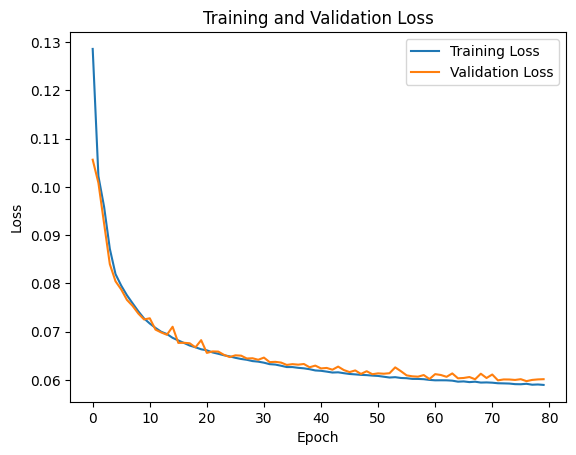

In [19]:
plt.figure()
plt.plot(train_loss_history, label='Training Loss')
plt.plot(val_loss_history, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

In [20]:
model.eval()

idx = 3
aux_single = train_aux[idx]
single_input = train_inputs[idx]  # Shape: (9, 4, 12)
aux_single = torch.tensor(aux_single, dtype=torch.float32)
single_input = torch.tensor(single_input, dtype=torch.float32)

# Add a batch dimension since the model expects a batch
aux_single = aux_single.unsqueeze(0)  # Shape: (1, 9, 4, 12)
single_input = single_input.unsqueeze(0)  # Shape: (1, 9, 4, 12)

# Make sure no gradients are computed during inference
aux_single = aux_single.to(device)
single_input = single_input.to(device)
with torch.no_grad():
    prediction = model(single_input, aux_single)

# `prediction` now contains the output for this single input
print("Prediction:", prediction)
print("Real:", train_outputs[idx])

Prediction: tensor([[[0.4407],
         [0.4524],
         [0.6671],
         [0.6288],
         [0.8366],
         [0.4253],
         [0.3681],
         [0.2843],
         [0.6713]]], device='cuda:0')
Real: [[0.43478261]
 [0.48913043]
 [0.64793478]
 [0.63043478]
 [0.58695652]
 [0.36956522]
 [0.34684783]
 [0.30967391]
 [0.39141304]]


In [21]:
r2_scores = model.calculate_r2_score(test_loader)

for i, r2 in enumerate(r2_scores):
    print(f'R² for station {i+1}: {r2:.4f}')

print(f'Mean of R² scores: {sum(r2_scores)/len(r2_scores):.4f}')


R² for station 1: 0.7467
R² for station 2: 0.7427
R² for station 3: 0.9196
R² for station 4: 0.7122
R² for station 5: 0.6785
R² for station 6: 0.7293
R² for station 7: 0.8836
R² for station 8: 0.8982
R² for station 9: 0.8920
Mean of R² scores: 0.8003


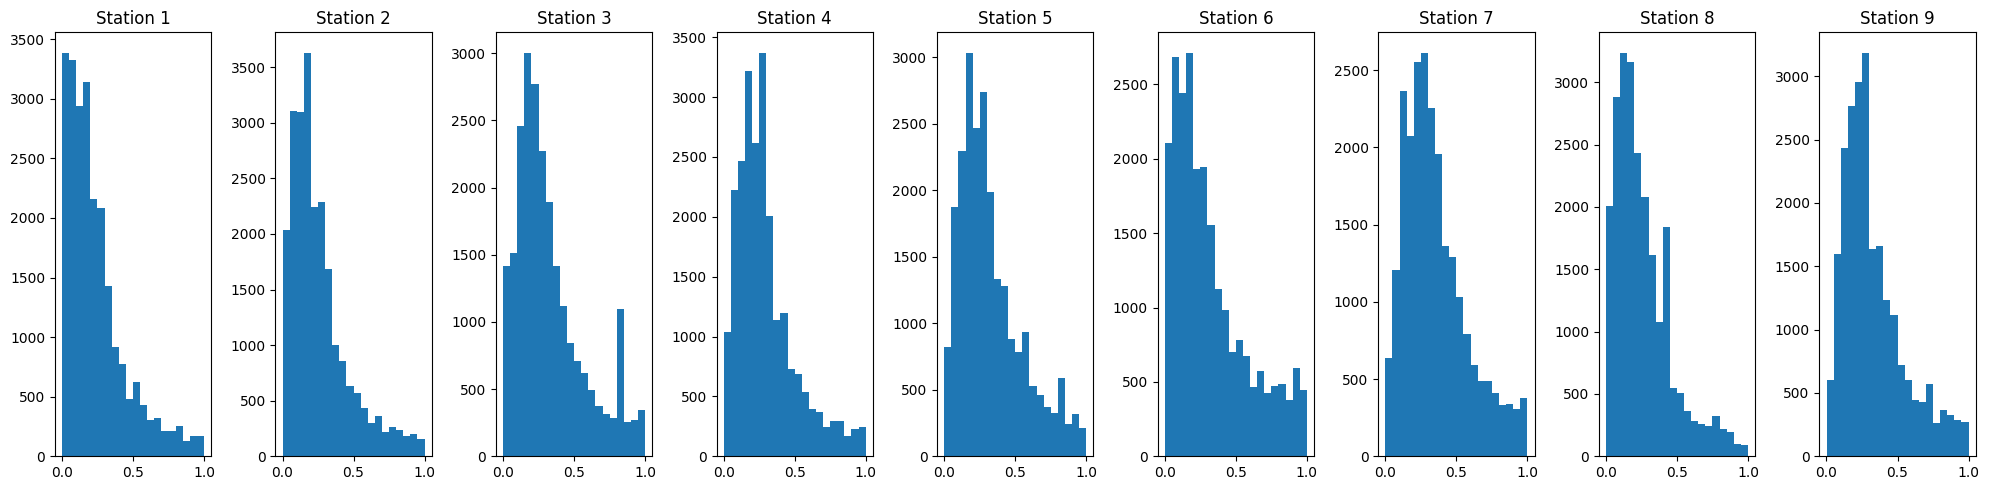

In [22]:
# plot station data distributions

station_groups = df.groupby('Station')['PM2.5']

fig, axes = plt.subplots(1, 9, figsize=(20, 5))

for i, (station, data) in enumerate(station_groups):
    axes[i].hist(data, bins=20)
    axes[i].set_title(f'Station {station}')

plt.tight_layout()
plt.show()


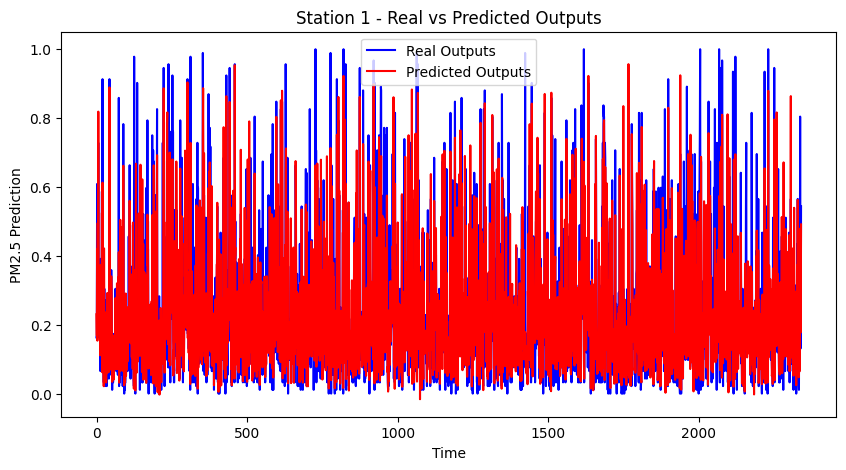

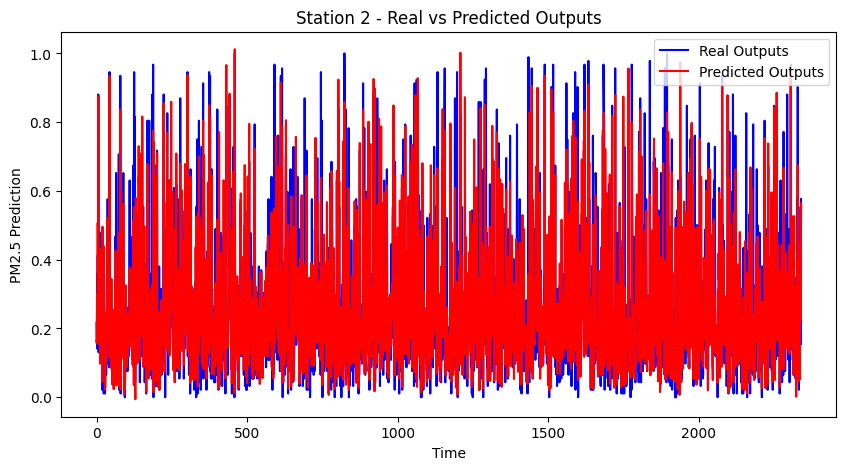

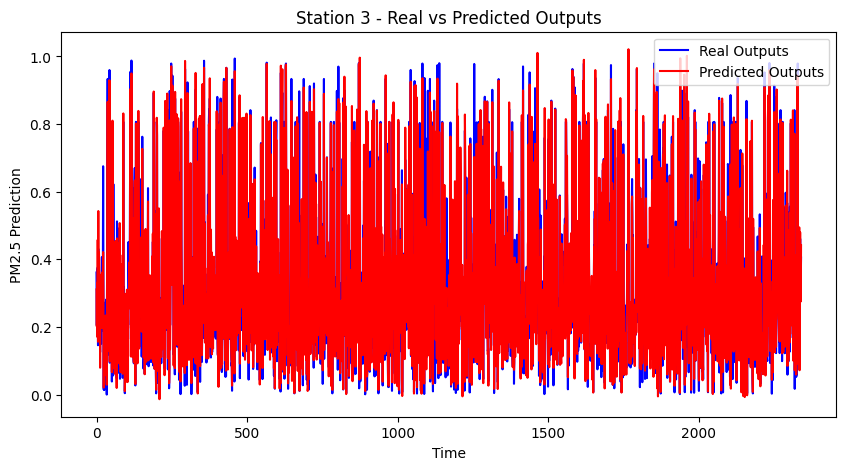

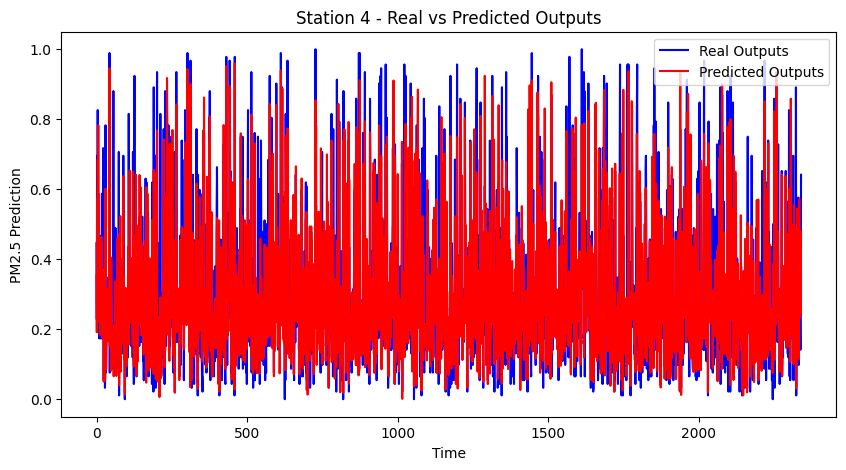

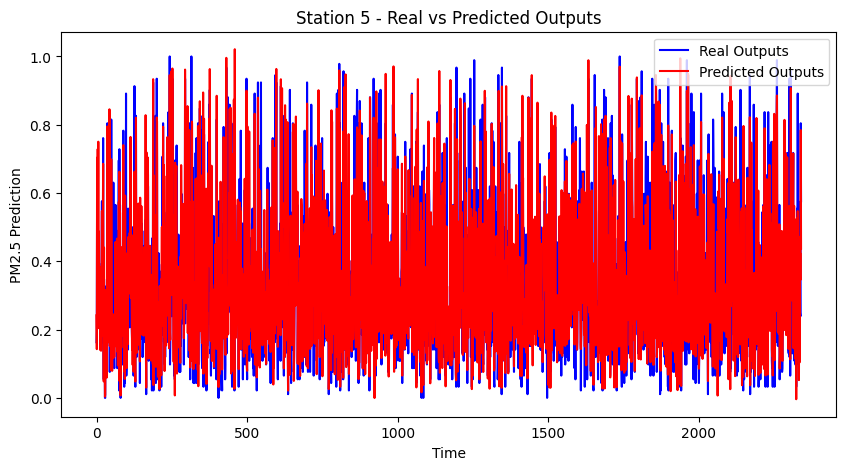

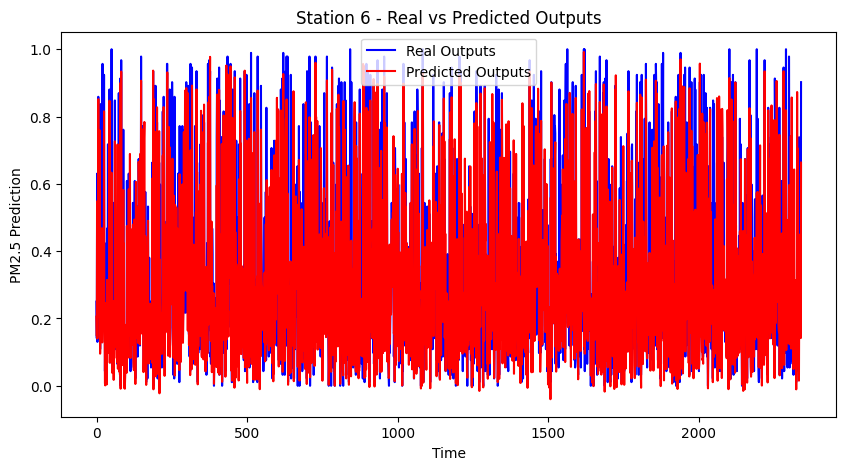

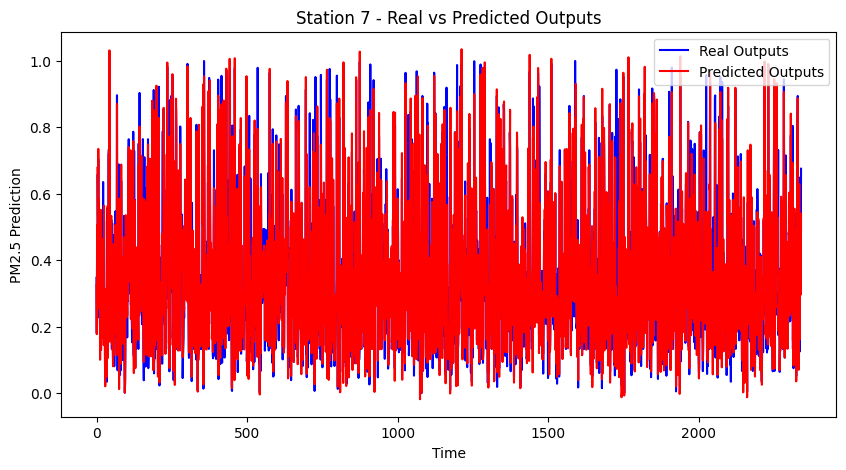

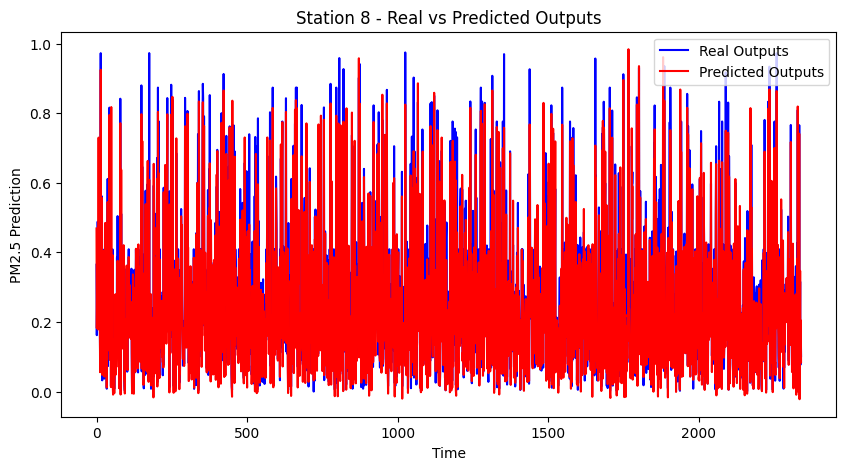

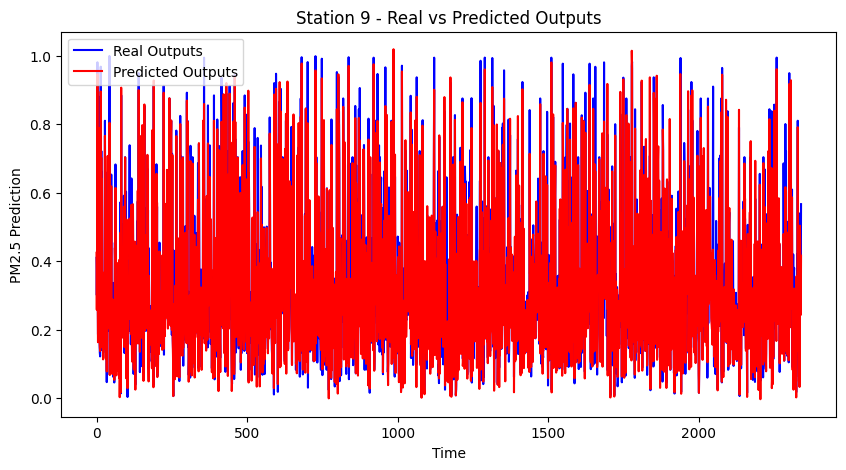

In [23]:
model.eval()

# Initialize lists to store real and predicted outputs
real_outputs = []
predicted_outputs = []

# Disable gradient calculations (for inference only)
with torch.no_grad():
    for inputs, aux_inputs, targets in val_loader:
        inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
        preds = model(inputs, aux_inputs)

        # Forward pass through the model to get predictions

        # Ensure the predictions are reshaped correctly to (batch_size, 9, 1)
        preds = preds.view(-1, 9, 1)

        # Store the real and predicted outputs (detach from GPU if necessary)
        real_outputs.append(targets.cpu().numpy())
        predicted_outputs.append(preds.cpu().numpy())

# Convert lists to numpy arrays
real_outputs = np.concatenate(real_outputs, axis=0)
predicted_outputs = np.concatenate(predicted_outputs, axis=0)

# Plotting continuous real vs predicted outputs for each station
for station_idx in range(9):
    plt.figure(figsize=(10, 5))
    plt.plot(real_outputs[:, station_idx, 0], label='Real Outputs', color='blue')
    plt.plot(predicted_outputs[:, station_idx, 0], label='Predicted Outputs', color='red')
    plt.title(f'Station {station_idx+1} - Real vs Predicted Outputs')
    plt.xlabel('Time')
    plt.ylabel('PM2.5 Prediction')
    plt.legend()
    plt.show()